In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


In [2]:

domainM='GRp';spin='spin2'
nx=10;ny=10

iyr=2000
fyr=2016

In [3]:
sourceData=f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'

if domainM =='GRq':
    ds_grM= xr.open_dataset('/home/santolam/NST.2000.01.01.00.GRc.nc')
elif domainM =='GRp':
    ds_grM= xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')

domain=domainM
LONS=ds_grM.LON[ny:-ny,nx:-nx].values
LATS=ds_grM.LAT[ny:-ny,nx:-nx].values
ds1_SH=ds_grM.SH[ny:-ny,nx:-nx]
ds1_ICE= ds_grM.ICE[ny:-ny,nx:-nx]

ds1_SH=ds1_SH.rename({'x':'X','y':'Y'})

ds1_ICE=ds1_ICE.rename({'x':'X','y':'Y'})
latS=LATS.min(); latN=LATS.max()
lonW=LONS.min(); lonE=LONS.max()

In [4]:

def compute_snowline_monthly(field1, dsSH, 
                             nosnow_thresh=1e-3, 
                             snow_thresh=1e-2, 
                             min_elev_mask=20,nbrpix=10,
                             name=None):
    """
    Compute monthly snowline (mean elevation of top10 no-snow and bottom10 snow pixels).
    
    Parameters
    ----------
    field1 : xarray.DataArray
        Snow depth data with dimensions (time, y, x).
    dsSH : xarray.DataArray
        Elevation field with dimensions (y, x).
    nosnow_thresh : float, optional
        Threshold below which there is no snow (default: 1e-3).
    snow_thresh : float, optional
        Threshold above which there is snow (default: 1e-2).
    min_elev_mask : float, optional
        Minimum elevation for valid snow points (default: 2000).
    name : str, optional
        Dataset name for labeling results.
        
    Returns
    -------
    pd.DataFrame
        Monthly mean elevations for no-snow, snow, and mean snowline.
    """

    # --- Compute monthly climatology ---
    clim_SHSN_month = field1.groupby('time.month').mean('time')

    months = np.arange(1, 13)
    mean_top10_all = []
    mean_bottom10_all = []
    mean_snowline_all = []

    for m in months:
        clim = clim_SHSN_month.sel(month=m)
        
        # --- No snow (snow depth < nosnow_thresh) ---
        no_snow_elev = dsSH.where(clim.values < nosnow_thresh)
        valid_no_snow = no_snow_elev.values.flatten()
        valid_no_snow = valid_no_snow[~np.isnan(valid_no_snow)]
        #print(valid_no_snow)
        if len(valid_no_snow) >= int(nbrpix):
            top10 = np.sort(valid_no_snow)[::-1][:int(nbrpix)]
            mean_top10 = np.mean(top10)
        else:
            print('No pixels without snow')
            mean_top10 = np.nan
        
        # --- Snow present (snow depth > snow_thresh) ---
        snow_elev = dsSH.where(clim.values > snow_thresh)
        valid_snow = snow_elev.values.flatten()
        valid_snow = valid_snow[~np.isnan(valid_snow)]
        
        if len(valid_snow) >= int(nbrpix):
            sorted_vals_bottom10 = np.sort(valid_snow)
            sorted_vals_bottom10 = sorted_vals_bottom10[sorted_vals_bottom10 >= min_elev_mask]
            if len(sorted_vals_bottom10) >= int(nbrpix):
                bottom10 = sorted_vals_bottom10[:int(nbrpix)]
                mean_bottom10 = np.mean(bottom10)
            else:
                print('No pixels withsnow')
                mean_bottom10 = np.nan
        else:
            mean_bottom10 = np.nan
        
        # Mean snowline (midpoint between no-snow and snow elevations)
        mean_snowline = np.nanmean([mean_top10, mean_bottom10])
        
        mean_top10_all.append(mean_top10)
        mean_bottom10_all.append(mean_bottom10)
        mean_snowline_all.append(mean_snowline)

    # --- Create DataFrame ---
    snowline_df = pd.DataFrame({
        'month': months,
        'mean_top10': mean_top10_all,
        'mean_bottom10': mean_bottom10_all,
        'mean_snowline': mean_snowline_all,
    })

    if name is not None:
        snowline_df['dataset'] = name

    return snowline_df


In [5]:

#modelList=['ESACCI','era5-land','HARv2','MAR']

In [6]:
modelList=['HMASR']

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/SNCD_clim_snowline_methods_HMASR_GRp_2000-2016.nc.png


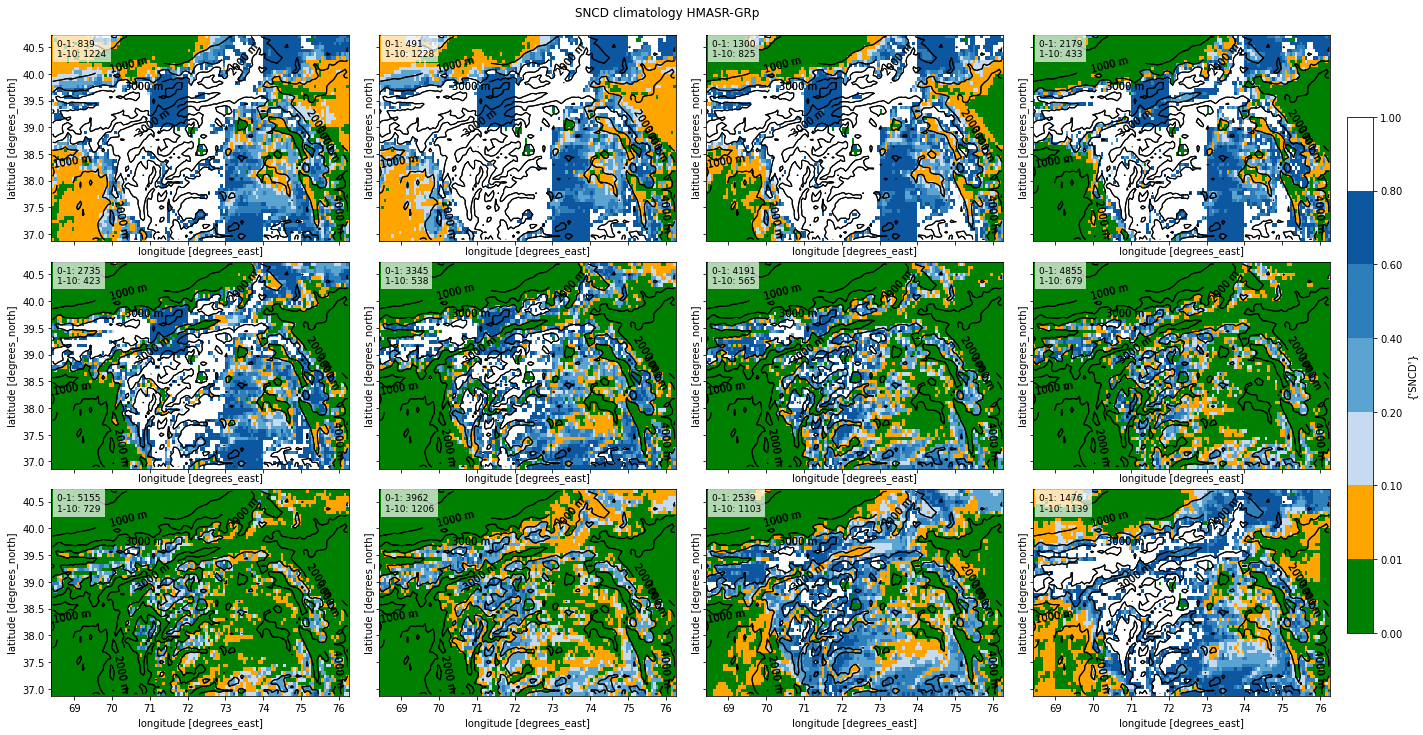

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/snowline_methods_nosnow_0.5_nbrpix_100_HMASR_GRp_2000-2016.nc.png


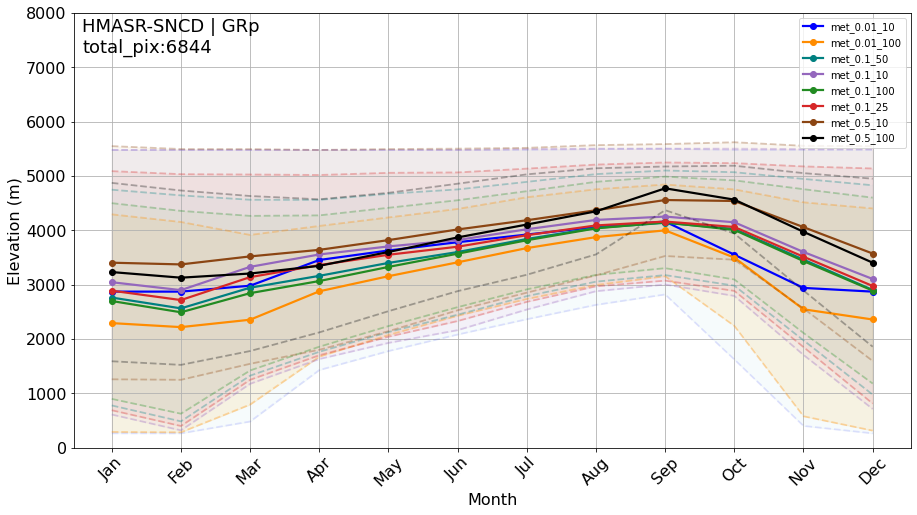

In [7]:


for model in modelList:
    if model=='ESACCI': 
        var='SNCF'
        sourceData2='/bettik/PROJECTS/pr-regional-climate/santolam/esacciv20/HMA/monthly/'
        ds2_HMA=xr.open_dataset(sourceData2+'1982-2018_ESACCI-L3C_SNOW-SCFG-AVHRR_MERGED-fv2.0_interp_HMA_mon.nc')
        ds2_SNC_raw=ds2_HMA['scfg_interp']
        ds2_SNC=ds2_SNC_raw.sel(lat=slice(latS,latN),lon=slice(lonW,lonE))
        ds_SNC_clim = ds2_SNC.groupby('time.month').mean('time')

        ds2_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_esacciv2_hma_grid.nc')['elevation']
        field2_SH=ds2_SH.sel(lat=slice(latS,latN),lon=slice(lonW,lonE))#dom.field_dom(ds2_SH,domain)
        total_pix=ds_SNC_clim.shape[1]*ds_SNC_clim.shape[2]
    
        ds_SNC_clim = ds2_SNC.groupby('time.month').mean('time')
        field1=ds2_SNC
        field1_SH=field2_SH

    elif model=='era5-land':
        var='SND'
        ds3_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/era5-land/' +
                         'snd_mon.era5-land_HMA_195001-202508.nc')['sde']
        ds3=ds3_raw.rename({'valid_time': 'time','latitude':'lat','longitude':'lon'})
        field3=ds3.sel(time=slice(str(iyr),str(fyr)))
        field3=field3.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
        field3=field3.where(field3>0)
        field3=field3
        ds3_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+
                       'gmted_on_t2m_era5-land_corrected.nc')['elevation']
        ds3_SH=ds3_SH.rename({'latitude':'lat','longitude':'lon'})
        field3_SH=ds3_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
        ds3_ICE=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/era5-land/' +
                        'glacier_mask.era5-land_01x01.nc')['glm'][0,:,:]
        ds3_ICE=ds3_ICE.rename({'latitude':'lat','longitude':'lon'})
        field3_ICE=100*ds3_ICE.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
        ds_SNC_clim = field3.groupby('time.month').mean('time')
        total_pix=ds_SNC_clim.shape[1]*ds_SNC_clim.shape[2]
        field1=field3
        field1_SH=field3_SH

    elif model=='HARv2':
        var='SND'
        model7=model
        res7='10kmx10km'

        sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/'
        fileName='HARv2_mon_d10km_d_2d_snowh_1980-2023.nc'
        ds7= xr.open_dataset(sourceData+'/'+model7+'/'+fileName)['snowh']
        def xy_sel_dom(ds,latS,latN,lonW,lonE):
    #latS,latN,lonW,lonE,latlim,lonlim=dom.coord_domain(domain)
            lat_str = ''
            lon_str = ''
            other_dims_str = []
            for dim in ds.coords:
                print(dim)
                if dim in ['lat', 'latitude','LON']:
                    lat_str = dim
                elif dim in ['lon', 'longitude','LAT']:
                    lon_str = dim
                else:
                    other_dims_str.append(dim)
            mask = (
                (latS < ds[lat_str]) & ( ds[lat_str] < latN) 
            & (lonW < ds[lon_str]) & ( ds[lon_str] < lonE)
            )
            field_dom=ds.where(mask,drop=True)
            return field_dom


        field7=xy_sel_dom(ds7.sel(time=slice(str(iyr),str(fyr))),latS,latN,lonW,lonE)
        fileName7_grF='HARv2_d10km_static_hgt.nc'
        ds7_grM= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7_grF)
        ds7SH=ds7_grM['hgt'][0,:,:]
        field7_SH=xy_sel_dom(ds7SH,latS,latN,lonW,lonE)
    
        ds_SNC_clim = field7.groupby('time.month').mean('time')
        total_pix=ds_SNC_clim.shape[1]*ds_SNC_clim.shape[2]
        field1=field7
        field1_SH=field7_SH

    elif model == 'HMASR' and domainM == 'GRq':
        var='SNCD'
        domain='CH'
        imon=1;iday=1;fmon=12;fday=31
        model4='hmasr'
        res4=str('5kmx5km')
        sourceData4='/bettik/PROJECTS/pr-regional-climate/santolam/HMA_SR_daily_7km_'+domain+'/'
        ds4_raw=xr.open_mfdataset(sourceData4+'/snow_bin/'+
                    #f'snd_bin_HMA_SR_D_v01_WY*_*_{domain}_lat35N43N_lon66E79E_SD_POST_MASKED_coarsen15x15.nc')['SD_Post']
                f'snd_bin_HMA_SR_D_v01_WY*_*_{domain}_lat24N32N_lon80E91E_SD_POST_MASKED_coarsen15x15.nc')['SD_Post']
    
        field4=ds4_raw.sel(lat=slice(latS,latN),lon=slice(lonW,lonE))
        field4=field4.sel(time=slice(str(iyr), str(fyr)))

        ds4_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+f'gmted_on_hma_sr_{domain}_7km.nc')['elevation']
        field4_SH=ds4_SH_raw.sel(lat=slice(latS,latN),lon=slice(lonW,lonE))
        ds_SNC_clim = field4.groupby('time.month').mean('time')
        total_pix=ds_SNC_clim.shape[1]*ds_SNC_clim.shape[2]
        field1=field4
        field1_SH=field4_SH
    elif model == 'HMASR' and domainM == 'GRp':
        var='SNCD'
        domain='HK'
        imon=1;iday=1;fmon=12;fday=31
        model4='hmasr'
        res4=str('5kmx5km')
        sourceData4='/bettik/PROJECTS/pr-regional-climate/santolam/HMA_SR_daily_7km_'+domain+'/'
        ds4_raw=xr.open_mfdataset(sourceData4+'/snow_bin/'+
               f'snd_bin_HMA_SR_D_v01_WY*_*_{domain}_lat35N43N_lon66E79E_SD_POST_MASKED_coarsen15x15.nc')['SD_Post']
            #f'snd_bin_HMA_SR_D_v01_WY*_*_{domain}_lat24N32N_lon80E91E_SD_POST_MASKED_coarsen15x15.nc')['SD_Post']

        field4=ds4_raw.sel(lat=slice(latS,latN),lon=slice(lonW,lonE))
        field4=field4.sel(time=slice(str(iyr), str(fyr)))
        ds4_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+f'gmted_on_hma_sr_{domain}_7km.nc')['elevation']

        field4_SH=ds4_SH_raw.sel(lat=slice(latS,latN),lon=slice(lonW,lonE))
        ds_SNC_clim = field4.groupby('time.month').mean('time')
        total_pix=ds_SNC_clim.shape[1]*ds_SNC_clim.shape[2]
        field1=field4
        field1_SH=field4_SH

    elif model=='MAR':
        sourceData=f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'
        ds_SHSN_raw=xr.open_mfdataset(sourceData+
                            f'SHSN3_monmean_MARv3.14_ER5_spin2_'+domainM+'_*.nc')['SHSN3'].sel(SECTOR=2)
        ds_SHSN = ds_SHSN_raw.rename({'TIME': 'time'})
        ds_SHSN=ds_SHSN.sel(time=slice(str(iyr), str(fyr)))
        ds_SHSN=ds_SHSN[:,ny:-ny,nx:-nx]
        units_SHSN=ds_SHSN.units
        ds_SNC_clim = ds_SHSN.groupby('time.month').mean('time')
        total_pix=ds_SNC_clim.shape[1]*ds_SNC_clim.shape[2]
        field1=ds_SHSN
        field1_SH=ds1_SH
    
# Boundaries (in % snow cover)
    if model=='ESACCI':
        bounds = [0, 1, 10, 20, 40, 60, 80, 100]
    else:
        bounds = np.array([0, 1, 10, 20, 40, 60, 80, 100]) / 100.
    blues = plt.cm.Blues(np.linspace(0.4, 1, 5))

    colors = [
    "green",        # 0–1
    "orange",       # 1–10
    "#c6dbef",      # 10–20 (light blue transition)
    *blues          # 20–40, 40–60, 60–80, 80–100
    ]

    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    g = ds_SNC_clim.plot(col='month',col_wrap=4,cmap=cmap,norm=norm,
    cbar_kwargs={
        'label': {var},
        'ticks': bounds})
    levels = np.arange(1000, 8001, 1000)  # adapt to your elevations
    for ax, month in zip(g.axes.flat, ds_SNC_clim.month.values):

        cs = field1_SH.plot.contour(
            ax=ax,
            levels=levels,
            colors='k',
            linewidths=1.1,
            add_colorbar=False
        )

        ax.clabel(cs, fmt='%d m', fontsize=10, inline=True, colors='k')

        # values for this month only
        vals = ds_SNC_clim.sel(month=month).values.ravel()
        vals = vals[np.isfinite(vals)]

        counts, _ = np.histogram(vals, bins=bounds)

        n01 = counts[0]      # 0-1 %
        n110 = counts[1]     # 1-10 %

        ax.text(
            0.02, 0.98,
            f'0-1: {n01}\n1-10: {n110}',
            transform=ax.transAxes,
            fontsize=9,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
        )
    
    levels = np.arange(1000, 8001, 1000)  # adapt to your elevations

    for ax in g.axes.flat:
        cs = field1_SH.plot.contour(ax=ax,levels=levels,colors='k',
        linewidths=1.1,add_colorbar=False )

        ax.clabel( cs,fmt='%d m',fontsize=10,inline=True,colors='k')

    width_cm=48;height_cm=26
    g.fig.set_size_inches(width_cm/2.54, height_cm/2.54)
    g.fig.subplots_adjust(wspace=0.1, hspace=0.1)
    g.cbar.ax.set_position([1., 0.15, 0.02, 0.7])

    plt.suptitle(f'{var} climatology {model}-{domainM}',y=1)
    plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
    plotname=f'{var}_clim_snowline_methods_{model}_{domainM}_{iyr}-{fyr}.nc'

    plt.savefig(f"{plotsDir}{plotname}.png",
            bbox_inches="tight", dpi=300)

    print(f"Saved: {plotsDir}{plotname}.png")

    plt.show()
    
    nosnow_thresh=0.01 # 
    snow_thresh=0.01 #1%
    nbrpix=10
    met1=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met1=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met1['mean_snowline'].mean()
    snowline_df1_met1['mean_top10'].mean()
    snowline_df1_met1['mean_bottom10'].mean()
    snowline_df1_met1.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met1}.csv", index=False)

    nosnow_thresh=0.01 # 
    snow_thresh=0.01 #1%
    nbrpix=100
    met2=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met2=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met2['mean_snowline'].mean()
    snowline_df1_met2['mean_top10'].mean()
    snowline_df1_met2['mean_bottom10'].mean()
    snowline_df1_met2.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met2}.csv", index=False)
    
    nosnow_thresh=0.1 # 
    snow_thresh=0.1 #1%
    nbrpix=50
    met6=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met6=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met6['mean_snowline'].mean()
    snowline_df1_met6['mean_top10'].mean()
    snowline_df1_met6['mean_bottom10'].mean()
    snowline_df1_met6.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met6}.csv", index=False)
    
    nosnow_thresh=0.1 # 
    snow_thresh=0.1 #1%
    nbrpix=10
    met5=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met5=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met5['mean_snowline'].mean()
    snowline_df1_met5['mean_top10'].mean()
    snowline_df1_met5['mean_bottom10'].mean()
    snowline_df1_met5.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met5}.csv", index=False)

    nosnow_thresh=0.1 # 
    snow_thresh=0.1 #10%
    nbrpix=100
    met3=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met3=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met3['mean_snowline'].mean()
    snowline_df1_met3['mean_top10'].mean()
    snowline_df1_met3['mean_bottom10'].mean()
    snowline_df1_met3.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met3}.csv", index=False)
    
    nosnow_thresh=0.1 # 
    snow_thresh=0.1 #10%
    nbrpix=25
    met4=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met4=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met4['mean_snowline'].mean()
    snowline_df1_met4['mean_top10'].mean()
    snowline_df1_met4['mean_bottom10'].mean()
    snowline_df1_met4.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met4}.csv", index=False)
    
    nosnow_thresh=0.5 # 
    snow_thresh=0.5 #10%
    nbrpix=10
    met7=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met7=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met7['mean_snowline'].mean()
    snowline_df1_met7['mean_top10'].mean()
    snowline_df1_met7['mean_bottom10'].mean()
    snowline_df1_met7.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met7}.csv", index=False)

    nosnow_thresh=0.5 # 
    snow_thresh=0.5 #10%
    nbrpix=100
    met8=f'met_{snow_thresh}_{nbrpix}'
    snowline_df1_met8=compute_snowline_monthly(field1, field1_SH, nosnow_thresh=nosnow_thresh, snow_thresh=snow_thresh,nbrpix=nbrpix, min_elev_mask=10,name=None)
    snowline_df1_met8['mean_snowline'].mean()
    snowline_df1_met8['mean_top10'].mean()
    snowline_df1_met8['mean_bottom10'].mean()
    snowline_df1_met8.to_csv(f"/home/santolam/RECAP/results/snowline_tables/snowline_{model}_{domainM}_{met8}.csv", index=False)

    fig=plt.figure(figsize=(15,8))
    # Plot lines
    plt.plot(snowline_df1_met1['month'], snowline_df1_met1['mean_snowline'], marker='o',color="blue", 
             linewidth=2.2, linestyle="-", label=f"{met1}")
    plt.plot(snowline_df1_met1['month'], snowline_df1_met1['mean_bottom10'],
             linestyle="--", color="blue", alpha=0.1,linewidth=1.8)#label="Lowest 10 snowy pixels",
    plt.plot(snowline_df1_met1['month'], snowline_df1_met1['mean_top10'], 
             linestyle="--",color="blue", alpha=0.1,linewidth=1.8)#label="Highest 10 snow-free pixels", 
    plt.fill_between(snowline_df1_met1['month'], snowline_df1_met1['mean_bottom10'], snowline_df1_met1['mean_top10'], 
                     color="lightblue", alpha=0.1)#, label="Snow-covered elevation range")

    ######
    # met2
    plt.plot(snowline_df1_met2['month'], snowline_df1_met2['mean_snowline'],
             marker='o', color="darkorange",
             linewidth=2.2, linestyle="-", label=f"{met2}")

    plt.plot(snowline_df1_met2['month'], snowline_df1_met2['mean_bottom10'],
             linestyle="--", color="darkorange",
             alpha=0.3, linewidth=1.8)

    plt.plot(snowline_df1_met2['month'], snowline_df1_met2['mean_top10'],
             linestyle="--", color="darkorange",
             alpha=0.3, linewidth=1.8)

    plt.fill_between(snowline_df1_met2['month'],
                     snowline_df1_met2['mean_bottom10'],
                     snowline_df1_met2['mean_top10'],color="orange", alpha=0.1)
    #'''
    plt.plot(snowline_df1_met6['month'], snowline_df1_met6['mean_snowline'],
             marker='o', color="teal",
             linewidth=2.2, linestyle="-", label=f"{met6}")

    plt.plot(snowline_df1_met6['month'], snowline_df1_met6['mean_bottom10'],
             linestyle="--", color="teal",
             alpha=0.3, linewidth=1.8)

    plt.plot(snowline_df1_met6['month'], snowline_df1_met6['mean_top10'],
             linestyle="--", color="teal",
             alpha=0.3, linewidth=1.8)

    plt.fill_between(snowline_df1_met6['month'],
                     snowline_df1_met6['mean_bottom10'],
                     snowline_df1_met6['mean_top10'],
                     color="paleturquoise", alpha=0.1)
    #'''
    ##met5
    plt.plot(snowline_df1_met5['month'], snowline_df1_met5['mean_snowline'],
             marker='o', color="tab:purple",
             linewidth=2.2, linestyle="-", label=f"{met5}")

    plt.plot(snowline_df1_met5['month'], snowline_df1_met5['mean_bottom10'],
             linestyle="--", color="tab:purple",
             alpha=0.3, linewidth=1.8)

    plt.plot(snowline_df1_met5['month'], snowline_df1_met5['mean_top10'],
             linestyle="--", color="tab:purple",
             alpha=0.3, linewidth=1.8)

    plt.fill_between(snowline_df1_met5['month'],
                     snowline_df1_met5['mean_bottom10'],
                     snowline_df1_met5['mean_top10'],
                     color="plum", alpha=0.1)


    # met3
    plt.plot(snowline_df1_met3['month'], snowline_df1_met3['mean_snowline'],
             marker='o', color="forestgreen",
             linewidth=2.2, linestyle="-", label=f"{met3}")

    plt.plot(snowline_df1_met3['month'], snowline_df1_met3['mean_bottom10'],
             linestyle="--", color="forestgreen",
             alpha=0.3, linewidth=1.8)

    plt.plot(snowline_df1_met3['month'], snowline_df1_met3['mean_top10'],
             linestyle="--", color="forestgreen",
             alpha=0.3, linewidth=1.8)

    plt.fill_between(snowline_df1_met3['month'],
                     snowline_df1_met3['mean_bottom10'],
                     snowline_df1_met3['mean_top10'],
                     color="lightgreen", alpha=0.1)
    ######
    #'''
    plt.plot(snowline_df1_met4['month'], snowline_df1_met4['mean_snowline'],
             marker='o', color="tab:red",
             linewidth=2.2, linestyle="-", label=f"{met4}")

    plt.plot(snowline_df1_met4['month'], snowline_df1_met4['mean_bottom10'],
             linestyle="--", color="tab:red",
             alpha=0.3, linewidth=1.8)

    plt.plot(snowline_df1_met4['month'], snowline_df1_met4['mean_top10'],
             linestyle="--", color="tab:red",
             alpha=0.3, linewidth=1.8)

    plt.fill_between(snowline_df1_met4['month'],
                     snowline_df1_met4['mean_bottom10'],
                     snowline_df1_met4['mean_top10'],
                     color="lightcoral", alpha=0.1)
        ######
    # met7
    plt.plot(snowline_df1_met7['month'], snowline_df1_met7['mean_snowline'],
             marker='o', color="saddlebrown",
             linewidth=2.2, linestyle="-", label=f"{met7}")

    plt.plot(snowline_df1_met7['month'], snowline_df1_met7['mean_bottom10'],
             linestyle="--", color="saddlebrown",
             alpha=0.3, linewidth=1.8)

    plt.plot(snowline_df1_met7['month'], snowline_df1_met7['mean_top10'],
             linestyle="--", color="saddlebrown",
             alpha=0.3, linewidth=1.8)

    plt.fill_between(snowline_df1_met7['month'],
                     snowline_df1_met7['mean_bottom10'],
                     snowline_df1_met7['mean_top10'],
                     color="burlywood", alpha=0.1)

    ######
    # met8
    plt.plot(snowline_df1_met8['month'], snowline_df1_met8['mean_snowline'],
             marker='o', color="black",
             linewidth=2.2, linestyle="-", label=f"{met8}")

    plt.plot(snowline_df1_met8['month'], snowline_df1_met8['mean_bottom10'],
             linestyle="--", color="black",
             alpha=0.3, linewidth=1.8)

    plt.plot(snowline_df1_met8['month'], snowline_df1_met8['mean_top10'],
             linestyle="--", color="black",
             alpha=0.3, linewidth=1.8)

    plt.fill_between(snowline_df1_met8['month'],
                     snowline_df1_met8['mean_bottom10'],
                     snowline_df1_met8['mean_top10'],
                     color="lightgray", alpha=0.1)
    #'''
    ######

    ######
    plt.xlabel('Month',fontsize=16)
    #plt.xticks(np.arange(1,13,1),fontsize=16)
    plt.xticks(
        ticks=np.arange(1, 13, 1),
        labels=['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec'],
        rotation=45,
        fontsize=16
    )
    plt.yticks(fontsize=16)
    plt.ylim(0,8000)
    plt.ylabel('Elevation (m)',fontsize=16)
    plt.legend(loc='upper right')
    #plt.title(f'Annual cycle of snowline elevation {domainM}')
    plt.text(0.01, 0.99, f'{model}-{var} | {domainM} \ntotal_pix:{total_pix}', fontsize=18, 
             transform=plt.gca().transAxes,
             horizontalalignment='left', 
             verticalalignment='top')
    ####
    plt.grid(True)
    plt.grid(True)
    plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
    plotname=f'snowline_methods_nosnow_{nosnow_thresh}_nbrpix_{nbrpix}_{model}_{domainM}_{iyr}-{fyr}.nc'

    plt.savefig(f"{plotsDir}{plotname}.png",
                bbox_inches="tight", dpi=300)

    print(f"Saved: {plotsDir}{plotname}.png")

    plt.show()

